In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("data/Unfallorte_2025.csv", sep=";")

/var/folders/lt/9bfg8tyd2dx_4wgd0b7wqtlc0000gp/T/ipykernel_90457/3812728346.py:1: DtypeWarning: Columns (0: UIDENTSTLAE) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("data/Unfallorte_2025.csv", sep=";")


In [3]:
df.head(10)

,UIDENTSTLAE,ULAND,UREGBEZ,UKREIS,UGEMEINDE,UJAHR,UMONAT,USTUNDE,UWOCHENTAG,UKATEGORIE,...,IstPKW,IstFuss,IstKrad,IstGkfz,IstSonstige,LINREFX,LINREFY,XGCSWGS84,YGCSWGS84,PLST
0,01250509171013352025,1,0,60,7,2025,5,15,6,3,...,1,0,0,0,0,"578658,645899999886751","5975441,506100000813603","10,197759334000068","53,921402971000077",1
1,01250405161013752025,1,0,62,53,2025,4,14,7,3,...,0,0,0,0,0,"577747,035899999551475","5933250,982200000435114","10,173275287000024","53,542398901000070",1
2,01250118171013142025,1,0,56,15,2025,1,9,7,3,...,1,0,0,0,0,"543500,281399999745190","5955819,687799999490380","9,659670060000053","53,749196565000034",1
3,01250326152013912025,1,0,55,28,2025,3,16,4,3,...,1,1,0,0,0,"601362,065600000321865","6003468,873199999332428","10,552708229000075","54,169272189000083",1
4,01250225145013362025,1,0,58,116,2025,2,17,3,3,...,0,0,0,0,0,"565151,556099999696016","6035315,988099999725819","10,005090446000054","54,461325762000058",1
5,01250214145013972025,1,0,58,135,2025,2,10,6,3,...,1,0,0,0,0,"543412,027499999850988","6014894,672199999913573","9,666767379000021","54,280128178000041",1
6,01250213161013652025,1,0,53,41,2025,2,11,5,3,...,1,0,0,0,0,"613442,929800000041723","5965131,494999999180436","10,723392891000060","53,822328647000063",1
7,01250520171013162025,1,0,60,2,2025,5,16,3,2,...,1,0,0,0,1,"562253,739000000059605","5958774,414000000804663","9,944620876000045","53,773848553000050",1
8,01250120125013112025,1,0,1,0,2025,1,15,2,3,...,0,0,0,0,0,"528574,406899999827147","6070707,455399999395013","9,444298899000046","54,782754041000032",1
9,01250201105132612025,1,0,55,4,2025,2,15,7,3,...,1,0,0,0,0,"612523,510400000028312","5975436,281099999323487","10,713212153000029","53,915107704000036",1


In [4]:
df.count()

UIDENTSTLAE           273007
ULAND                 273007
UREGBEZ               273007
UKREIS                273007
UGEMEINDE             273007
UJAHR                 273007
UMONAT                273007
USTUNDE               273007
UWOCHENTAG            273007
UKATEGORIE            273007
UART                  273007
UTYP1                 273007
ULICHTVERH            273007
IstStrassenzustand    273007
IstRad                273007
IstPKW                273007
IstFuss               273007
IstKrad               273007
IstGkfz               273007
IstSonstige           273007
LINREFX               273007
LINREFY               273007
XGCSWGS84             273007
YGCSWGS84             273007
PLST                  273007
dtype: int64

In [5]:
df.duplicated().value_counts()

False    273007
Name: count, dtype: int64

In [6]:
df.dtypes

UIDENTSTLAE           object
ULAND                  int64
UREGBEZ                int64
UKREIS                 int64
UGEMEINDE              int64
UJAHR                  int64
UMONAT                 int64
USTUNDE                int64
UWOCHENTAG             int64
UKATEGORIE             int64
UART                   int64
UTYP1                  int64
ULICHTVERH             int64
IstStrassenzustand     int64
IstRad                 int64
IstPKW                 int64
IstFuss                int64
IstKrad                int64
IstGkfz                int64
IstSonstige            int64
LINREFX                  str
LINREFY                  str
XGCSWGS84                str
YGCSWGS84                str
PLST                   int64
dtype: object

In [7]:
df.isnull().values.any(), df.isnull().sum()

(np.False_,
 UIDENTSTLAE           0
 ULAND                 0
 UREGBEZ               0
 UKREIS                0
 UGEMEINDE             0
 UJAHR                 0
 UMONAT                0
 USTUNDE               0
 UWOCHENTAG            0
 UKATEGORIE            0
 UART                  0
 UTYP1                 0
 ULICHTVERH            0
 IstStrassenzustand    0
 IstRad                0
 IstPKW                0
 IstFuss               0
 IstKrad               0
 IstGkfz               0
 IstSonstige           0
 LINREFX               0
 LINREFY               0
 XGCSWGS84             0
 YGCSWGS84             0
 PLST                  0
 dtype: int64)

---
# EDA

Each row is **one accident** with at least one injured person.
Target-like column: `UKATEGORIE` (1 = killed, 2 = seriously injured, 3 = slightly injured).

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", rc={"axes.spines.top": False, "axes.spines.right": False,
                                      "grid.color": "#e6e5e1", "axes.edgecolor": "#b5b4ad"})
BLUE = "#2a78d6"                                  # single-series colour
SEV_COLORS = ["#811010", "#3987e5", "#4ea800"]    # killed / serious / slight (ordinal blue ramp)

## 1. Load with correct types
* `UIDENTSTLAE` is an ID with leading zeros → read as string (this also removes the mixed-type warning).
* Coordinates use a German decimal comma → `decimal=","`.

In [9]:
df = pd.read_csv("data/Unfallorte_2025.csv", sep=";", decimal=",", dtype={"UIDENTSTLAE": str})
print(df.shape)
df.dtypes

(273007, 25)


UIDENTSTLAE               str
ULAND                   int64
UREGBEZ                 int64
UKREIS                  int64
UGEMEINDE               int64
UJAHR                   int64
UMONAT                  int64
USTUNDE                 int64
UWOCHENTAG              int64
UKATEGORIE              int64
UART                    int64
UTYP1                   int64
ULICHTVERH              int64
IstStrassenzustand      int64
IstRad                  int64
IstPKW                  int64
IstFuss                 int64
IstKrad                 int64
IstGkfz                 int64
IstSonstige             int64
LINREFX               float64
LINREFY               float64
XGCSWGS84             float64
YGCSWGS84             float64
PLST                    int64
dtype: object

## 2. Merge the date fields into one `datetime` column

The file has `UJAHR` (year), `UMONAT` (month), `USTUNDE` (hour) and `UWOCHENTAG` (weekday, 1 = Sunday) – but **no day-of-month**.
The 20-character ID however is structured as `LL YYMMDD ...` (state, 2-digit year, month, day). We take the day from there and check it against the other date columns.

In [10]:
uid = df["UIDENTSTLAE"]
print("ID length:", uid.str.len().unique())
print("ID[0:2] == ULAND :", (uid.str[:2].astype(int) == df["ULAND"]).mean())
print("ID[2:4] == year  :", (uid.str[2:4].astype(int) + 2000 == df["UJAHR"]).mean())
print("ID[4:6] == month :", (uid.str[4:6].astype(int) == df["UMONAT"]).mean())

df["datetime"] = pd.to_datetime(dict(year=df["UJAHR"], month=df["UMONAT"],
                                     day=uid.str[6:8].astype(int), hour=df["USTUNDE"]),
                                errors="coerce")
print("unparseable dates:", df["datetime"].isna().sum())

# validate against the weekday column (pandas: Mon=0..Sun=6 -> Unfallatlas: Sun=1..Sat=7)
weekday_from_date = (df["datetime"].dt.dayofweek + 1) % 7 + 1
df["date_mismatch"] = weekday_from_date != df["UWOCHENTAG"]
print("weekday agrees with derived date:", 1 - df["date_mismatch"].mean())
df.loc[df["date_mismatch"], ["UIDENTSTLAE", "ULAND", "UMONAT", "UWOCHENTAG", "datetime"]]

ID length: [20]
ID[0:2] == ULAND : 1.0


ID[2:4] == year  : 1.0


ID[4:6] == month : 0.9999633709025776


unparseable dates: 0
weekday agrees with derived date: 0.9999706967220621


,UIDENTSTLAE,ULAND,UMONAT,UWOCHENTAG,datetime
105094,09250421004109128620,9,4,7,2025-04-21 15:00:00
110686,09250705003219291490,9,7,1,2025-07-05 02:00:00
117122,09251025004109540040,9,10,6,2025-10-25 22:00:00
216339,09250126002219028530,9,1,4,2025-01-26 06:00:00
216359,09250129008571022830,9,1,3,2025-01-29 07:00:00
226068,09250703008523271550,9,7,4,2025-07-03 10:00:00
227261,09250715008512385640,9,7,1,2025-07-15 17:00:00
252545,13250222314300690225,13,2,1,2025-02-22 04:00:00


The derived date agrees with the weekday for >99.99 % of rows, so the decoding is right. The 8 mismatches (7 in Bayern) are kept but flagged in `date_mismatch`.
Now the original date columns are dropped – everything is recoverable from `datetime`. `UJAHR` is constant (2025) anyway.

In [11]:
df = df.drop(columns=["UJAHR", "UMONAT", "USTUNDE", "UWOCHENTAG"])
df = df[["UIDENTSTLAE", "datetime"] + [c for c in df.columns if c not in ("UIDENTSTLAE", "datetime")]]
df.head()

,UIDENTSTLAE,datetime,ULAND,UREGBEZ,UKREIS,UGEMEINDE,UKATEGORIE,UART,UTYP1,ULICHTVERH,...,IstFuss,IstKrad,IstGkfz,IstSonstige,LINREFX,LINREFY,XGCSWGS84,YGCSWGS84,PLST,date_mismatch
0,01250509171013352025,2025-05-09 15:00:00,1,0,60,7,3,5,3,0,...,0,0,0,0,578658.6459,5.975442e+06,10.197759,53.921403,1,False
1,01250405161013752025,2025-04-05 14:00:00,1,0,62,53,3,0,7,0,...,0,0,0,0,577747.0359,5.933251e+06,10.173275,53.542399,1,False
2,01250118171013142025,2025-01-18 09:00:00,1,0,56,15,3,5,3,0,...,0,0,0,0,543500.2814,5.955820e+06,9.659670,53.749197,1,False
3,01250326152013912025,2025-03-26 16:00:00,1,0,55,28,3,6,2,0,...,1,0,0,0,601362.0656,6.003469e+06,10.552708,54.169272,1,False
4,01250225145013362025,2025-02-25 17:00:00,1,0,58,116,3,2,6,0,...,0,0,0,0,565151.5561,6.035316e+06,10.005090,54.461326,1,False


## 3. Decode categorical codes (labels from the PDF)

In [12]:
LABELS = {
    "ULAND": {1: "Schleswig-Holstein", 2: "Hamburg", 3: "Niedersachsen", 4: "Bremen", 5: "Nordrhein-Westfalen",
              6: "Hessen", 7: "Rheinland-Pfalz", 8: "Baden-Württemberg", 9: "Bayern", 10: "Saarland",
              11: "Berlin", 12: "Brandenburg", 13: "Mecklenburg-Vorpommern", 14: "Sachsen",
              15: "Sachsen-Anhalt", 16: "Thüringen"},
    "UKATEGORIE": {1: "killed", 2: "seriously injured", 3: "slightly injured"},
    "UART": {0: "other kind", 1: "with starting/stopping/stationary vehicle", 2: "with vehicle ahead/waiting",
             3: "with vehicle moving laterally, same dir.", 4: "with oncoming vehicle",
             5: "with turning/crossing vehicle", 6: "vehicle–pedestrian", 7: "with obstacle on carriageway",
             8: "leaving carriageway right", 9: "leaving carriageway left"},
    "UTYP1": {1: "driving accident", 2: "turning off", 3: "turning into / crossing", 4: "pedestrian crossing",
              5: "involving stationary", 6: "moving along in carriageway", 7: "other"},
    "ULICHTVERH": {0: "daylight", 1: "twilight", 2: "darkness"},
    "IstStrassenzustand": {0: "dry", 1: "wet/damp/slippery", 2: "slippery (winter)"},
    "PLST": {1: "regular", 2: "advanced (bicycle)"},
}
INVOLVED = ["IstRad", "IstPKW", "IstFuss", "IstKrad", "IstGkfz", "IstSonstige"]
INVOLVED_NAMES = {"IstRad": "bicycle", "IstPKW": "car", "IstFuss": "pedestrian",
                  "IstKrad": "motorcycle", "IstGkfz": "goods vehicle", "IstSonstige": "other"}

dfl = df.copy()   # labelled copy for plotting; df keeps the numeric codes
for col, mapping in LABELS.items():
    dfl[col] = pd.Categorical(df[col].map(mapping), categories=list(mapping.values()))
dfl["fatal"] = df["UKATEGORIE"].eq(1)
dfl["killed_or_serious"] = df["UKATEGORIE"].le(2)

## 4. Data quality overview

In [13]:
print("duplicate rows:", df.duplicated().sum(), "| duplicate IDs:", df["UIDENTSTLAE"].duplicated().sum())
print("missing values total:", df.isna().sum().sum())
pd.DataFrame({"dtype": df.dtypes.astype(str), "n_unique": df.nunique(), "min": df.min(numeric_only=True),
              "max": df.max(numeric_only=True)})

duplicate rows: 0 | duplicate IDs: 0
missing values total: 0


,dtype,n_unique,min,max
IstFuss,int64,2,0,1
IstGkfz,int64,2,0,1
IstKrad,int64,2,0,1
IstPKW,int64,2,0,1
IstRad,int64,2,0,1
IstSonstige,int64,2,0,1
IstStrassenzustand,int64,3,0,2
LINREFX,float64,269470,280434.2205,920210.3444
LINREFY,float64,269478,5240172.352275,6100338.237839
PLST,int64,2,1,2


In [14]:
# coordinate sanity: Germany lies roughly within lon 5.8–15.1, lat 47.2–55.1
lon, lat = df["XGCSWGS84"], df["YGCSWGS84"]
outside = ~(lon.between(5.8, 15.1) & lat.between(47.2, 55.1))
print("points outside Germany bounding box:", outside.sum())
df[["LINREFX", "LINREFY", "XGCSWGS84", "YGCSWGS84"]].describe()

points outside Germany bounding box: 0


,LINREFX,LINREFY,XGCSWGS84,YGCSWGS84
count,273007.000000,2.730070e+05,273007.000000,273007.000000
mean,549104.933113,5.636704e+06,9.701520,50.859482
std,151910.316367,1.970741e+05,2.173136,1.768320
min,280434.220500,5.240172e+06,5.867194,47.308169
25%,420808.683500,5.472213e+06,7.881520,49.393353
50%,531374.249000,5.658831e+06,9.449976,51.034495
75%,676738.976250,5.790455e+06,11.438347,52.246753
max,920210.344400,6.100338e+06,15.027292,55.048351


## 5. Target: accident severity (`UKATEGORIE`)

,count,share_%
UKATEGORIE,,
killed,2477,0.91
seriously injured,40430,14.81
slightly injured,230100,84.28


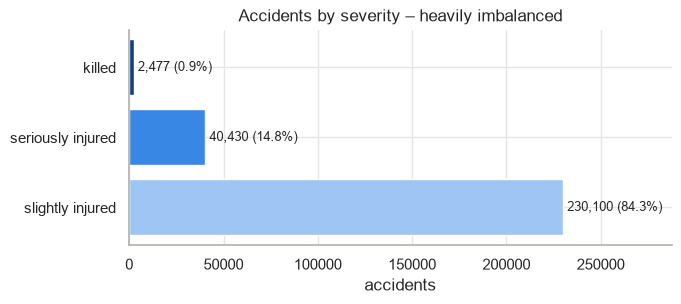

In [15]:
sev = dfl["UKATEGORIE"].value_counts().reindex(LABELS["UKATEGORIE"].values())
display(pd.DataFrame({"count": sev, "share_%": (sev / sev.sum() * 100).round(2)}))

fig, ax = plt.subplots(figsize=(7, 2.8))
ax.barh(sev.index, sev.values, color=SEV_COLORS)
for i, v in enumerate(sev.values):
    ax.text(v, i, f" {v:,} ({v / sev.sum():.1%})", va="center", fontsize=9)
ax.invert_yaxis(); ax.set_xlabel("accidents"); ax.set_title("Accidents by severity – heavily imbalanced")
ax.set_xlim(0, sev.max() * 1.25); plt.show()

Strong class imbalance: 0.9 % fatal, 14.8 % seriously injured, 84.3 % slightly injured. For modelling, a binary target such as
`killed_or_serious` (UKATEGORIE ≤ 2) is likely more workable than the 3-class target, and metrics like
precision/recall or PR-AUC are needed instead of accuracy.

## 6. Temporal patterns (from the merged `datetime`)

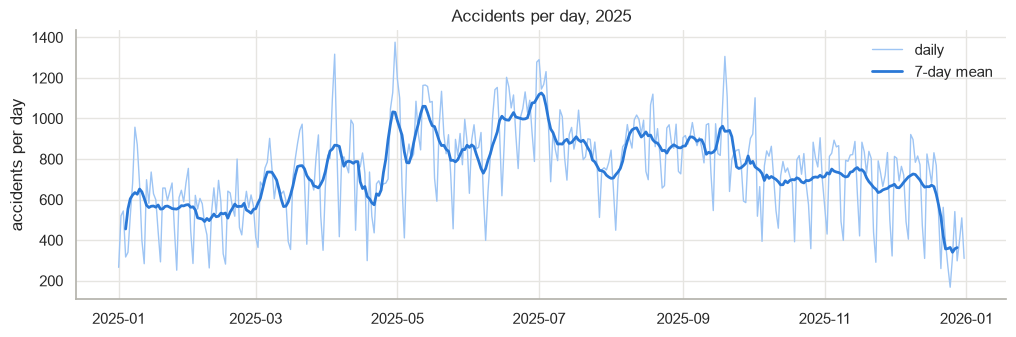

busiest days:
datetime
2025-04-30    1376
2025-04-04    1317
2025-09-19    1306
2025-07-01    1290
2025-06-30    1278
dtype: int64
quietest days:
datetime
2025-12-25    168
2025-01-26    252
2025-12-21    260
2025-02-09    263
2025-01-01    266
dtype: int64


In [16]:
t = dfl["datetime"]
daily = dfl.set_index("datetime").resample("D").size()
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(daily.index, daily.values, color="#9ec5f4", lw=1, label="daily")
ax.plot(daily.index, daily.rolling(7, center=True).mean(), color=BLUE, lw=2, label="7-day mean")
ax.set_ylabel("accidents per day"); ax.set_title("Accidents per day, 2025"); ax.legend(frameon=False)
plt.show()
print("busiest days:"); print(daily.nlargest(5))
print("quietest days:"); print(daily.nsmallest(5))

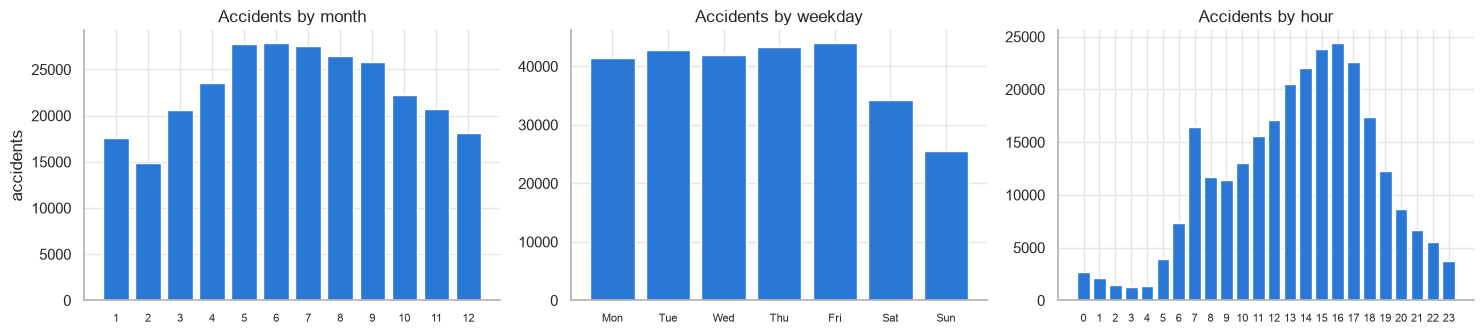

In [17]:
WD_ORDER = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
dfl["month"] = t.dt.month
dfl["weekday"] = pd.Categorical(t.dt.strftime("%a"), categories=WD_ORDER)
dfl["hour"] = t.dt.hour

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, col, title in zip(axes, ["month", "weekday", "hour"], ["by month", "by weekday", "by hour"]):
    counts = dfl[col].value_counts().sort_index()
    ax.bar(counts.index.astype(str), counts.values, color=BLUE)
    ax.set_title(f"Accidents {title}"); ax.tick_params(axis="x", labelsize=8)
axes[0].set_ylabel("accidents"); plt.tight_layout(); plt.show()

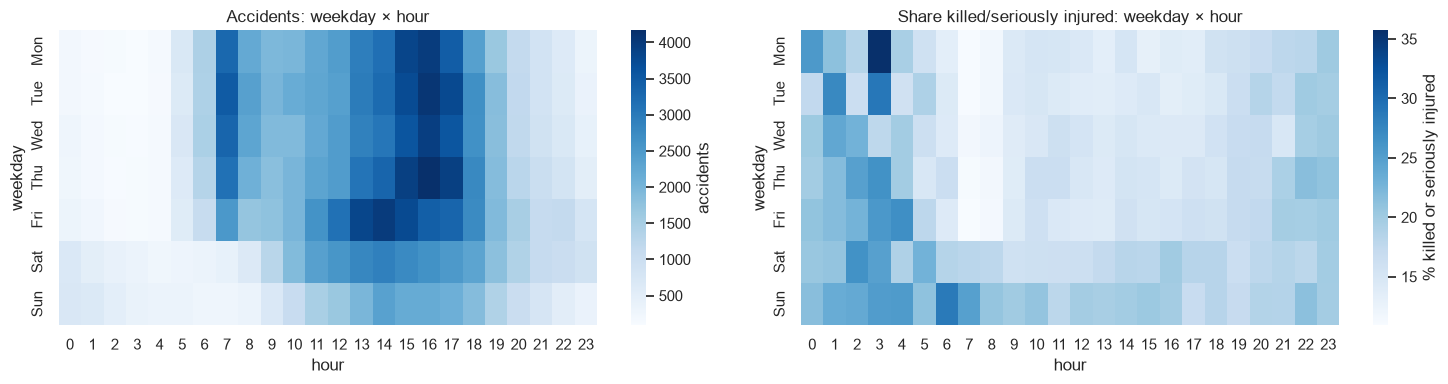

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
heat = pd.crosstab(dfl["weekday"], dfl["hour"])
sns.heatmap(heat, cmap="Blues", ax=axes[0], cbar_kws={"label": "accidents"})
axes[0].set_title("Accidents: weekday × hour")
heat_f = pd.crosstab(dfl["weekday"], dfl["hour"], values=dfl["killed_or_serious"], aggfunc="mean") * 100
sns.heatmap(heat_f, cmap="Blues", ax=axes[1], cbar_kws={"label": "% killed or seriously injured"})
axes[1].set_title("Share killed/seriously injured: weekday × hour")
plt.tight_layout(); plt.show()

Volume follows commuting patterns (peaks at 7 h and 15–17 h, more on weekdays and in May–Sep), but
**severity is highest at night (21–26 % killed/serious between 0 and 3 h vs. 12 % at 7 h) and on weekends (18–20 % vs. 14–15 %)** – fewer accidents, yet worse outcomes. Volume and severity tell different stories.

## 7. Accident circumstances – volume vs. severity

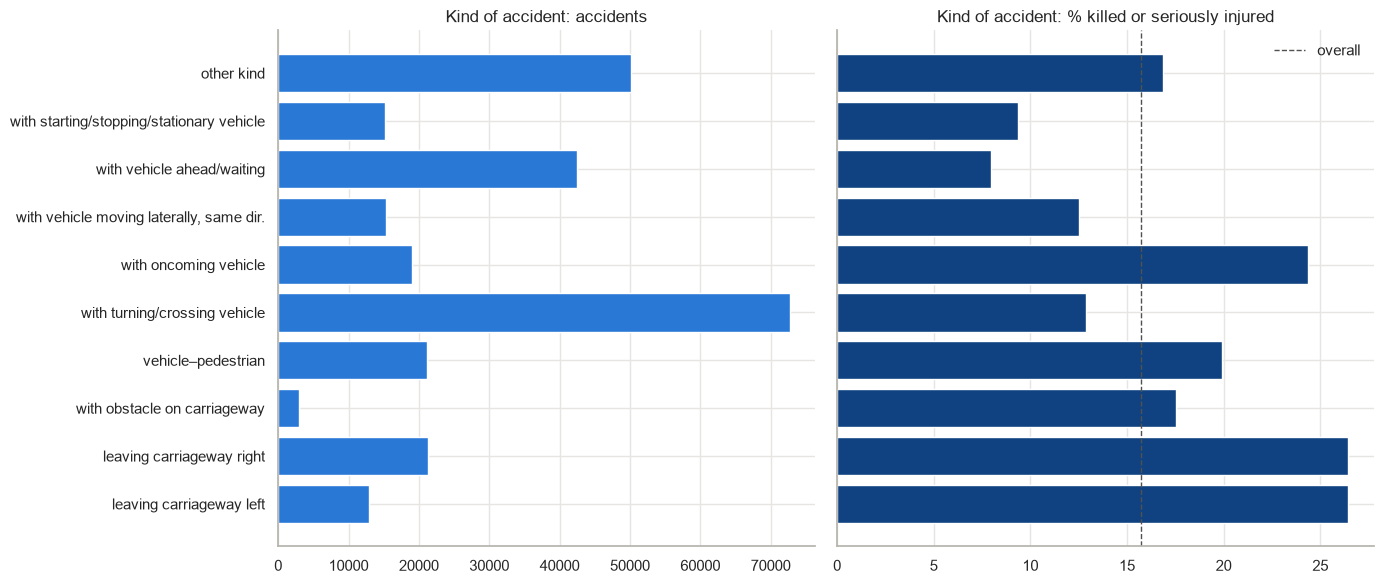

,n,% killed/serious,% fatal
UART,,,
other kind,50163,16.8,0.45
with starting/stopping/stationary vehicle,15124,9.4,0.29
with vehicle ahead/waiting,42448,8.0,0.42
"with vehicle moving laterally, same dir.",15275,12.5,0.48
with oncoming vehicle,18985,24.4,2.54
with turning/crossing vehicle,72677,12.9,0.54
vehicle–pedestrian,21104,19.9,1.54
with obstacle on carriageway,2992,17.5,1.04
leaving carriageway right,21292,26.5,2.06


In [19]:
def volume_and_severity(col, title, rot=False):
    g = dfl.groupby(col, observed=True).agg(n=("fatal", "size"), ks=("killed_or_serious", "mean"),
                                             fatal=("fatal", "mean"))
    fig, axes = plt.subplots(1, 2, figsize=(14, 0.45 * len(g) + 1.5), sharey=True)
    axes[0].barh(g.index.astype(str), g["n"], color=BLUE); axes[0].set_title(f"{title}: accidents")
    axes[1].barh(g.index.astype(str), g["ks"] * 100, color="#104281")
    axes[1].axvline(dfl["killed_or_serious"].mean() * 100, color="#52514e", ls="--", lw=1, label="overall")
    axes[1].set_title(f"{title}: % killed or seriously injured"); axes[1].legend(frameon=False)
    axes[0].invert_yaxis(); plt.tight_layout(); plt.show()
    return (g.assign(ks=lambda x: (x.ks * 100).round(1), fatal=lambda x: (x.fatal * 100).round(2))
             .rename(columns={"ks": "% killed/serious", "fatal": "% fatal"}))

volume_and_severity("UART", "Kind of accident")

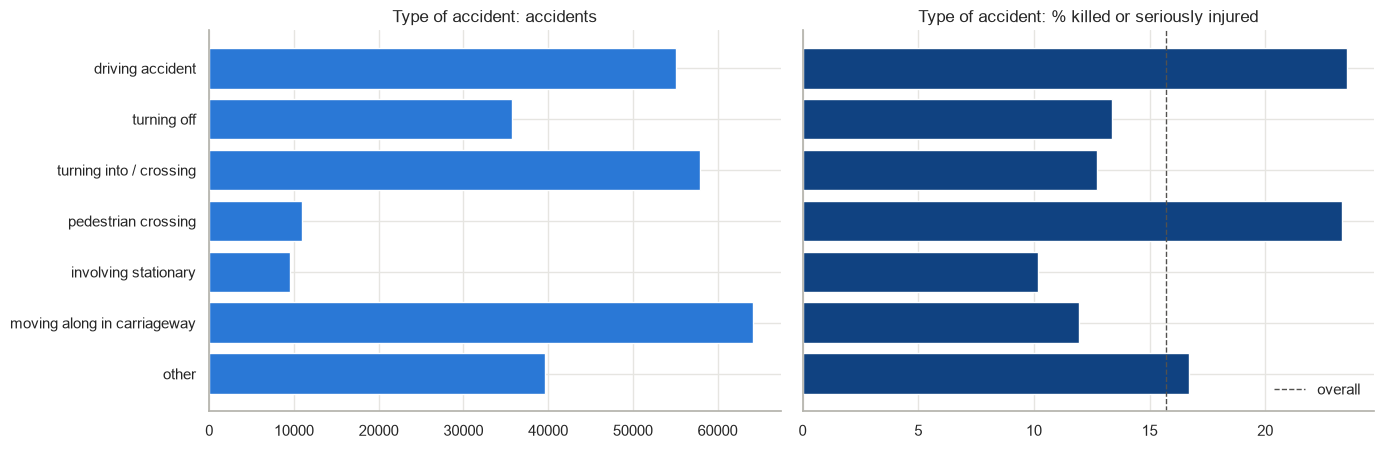

,n,% killed/serious,% fatal
UTYP1,,,
driving accident,55038,23.5,1.47
turning off,35676,13.4,0.48
turning into / crossing,57943,12.7,0.58
pedestrian crossing,10978,23.3,1.84
involving stationary,9502,10.2,0.33
moving along in carriageway,64220,11.9,0.94
other,39650,16.7,0.82


In [20]:
volume_and_severity("UTYP1", "Type of accident")

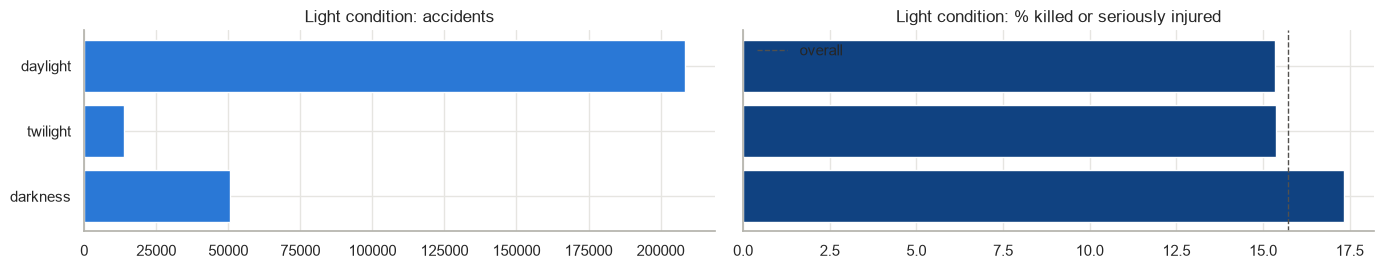

,n,% killed/serious,% fatal
ULICHTVERH,,,
daylight,208489,15.3,0.83
twilight,13965,15.4,0.84
darkness,50553,17.3,1.23


In [21]:
volume_and_severity("ULICHTVERH", "Light condition")

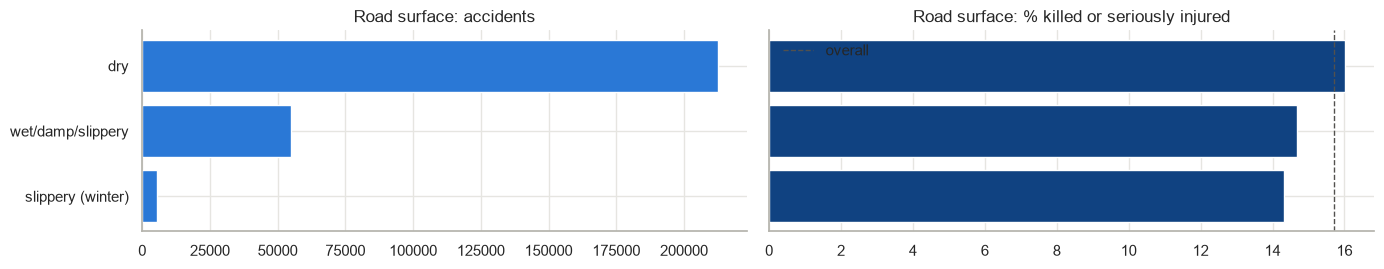

,n,% killed/serious,% fatal
IstStrassenzustand,,,
dry,212665,16.0,0.90
wet/damp/slippery,54919,14.7,0.95
slippery (winter),5423,14.3,0.53


In [22]:
volume_and_severity("IstStrassenzustand", "Road surface")

## 8. Who is involved? (`Ist*` flags)

,accidents,% of accidents,% killed/serious when involved,% fatal when involved
car,197598,72.4,13.78,0.86
bicycle,89521,32.8,15.01,0.50
other,39572,14.5,14.16,1.03
motorcycle,36698,13.4,24.78,1.44
pedestrian,24037,8.8,19.27,1.49
goods vehicle,10859,4.0,21.35,3.50


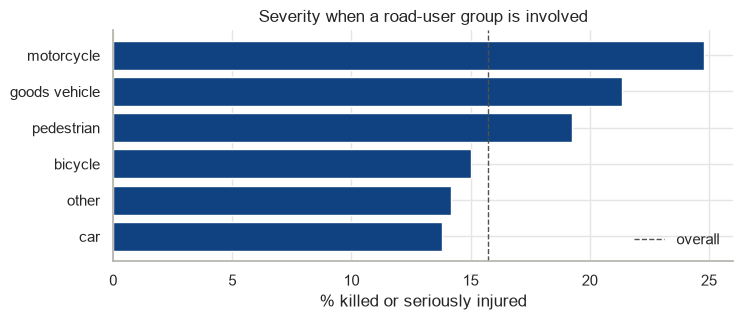

In [23]:
inv = pd.DataFrame({
    "accidents": df[INVOLVED].sum(),
    "% of accidents": (df[INVOLVED].mean() * 100).round(1),
    "% killed/serious when involved": [dfl.loc[df[c] == 1, "killed_or_serious"].mean() * 100 for c in INVOLVED],
    "% fatal when involved": [dfl.loc[df[c] == 1, "fatal"].mean() * 100 for c in INVOLVED],
}).rename(index=INVOLVED_NAMES).round(2).sort_values("accidents", ascending=False)
display(inv)

fig, ax = plt.subplots(figsize=(8, 3))
s = inv["% killed/serious when involved"].sort_values()
ax.barh(s.index, s.values, color="#104281")
ax.axvline(dfl["killed_or_serious"].mean() * 100, color="#52514e", ls="--", lw=1, label="overall")
ax.set_xlabel("% killed or seriously injured"); ax.set_title("Severity when a road-user group is involved")
ax.legend(frameon=False); plt.show()

In [24]:
# number of involved groups per accident and the most common combinations
n_groups = df[INVOLVED].sum(axis=1)
print("involved groups per accident:"); print(n_groups.value_counts().sort_index())
combo = df[INVOLVED].rename(columns=INVOLVED_NAMES).apply(lambda r: " + ".join(r.index[r == 1]) or "(none)", axis=1)
combo.value_counts().head(12)

involved groups per accident:
1    149064
2    122622
3      1307
4        14
Name: count, dtype: int64


car                     92262
bicycle + car           43241
bicycle                 34334
car + motorcycle        19135
car + other             19124
car + pedestrian        15501
motorcycle              13375
other                    8118
car + goods vehicle      7069
bicycle + other          5558
bicycle + pedestrian     4113
pedestrian + other       3237
Name: count, dtype: int64

Every accident has at least one flag set; ~45 % involve two groups (mostly car + something).
Motorcycles (24.8 %) and goods vehicles (21.4 %) have the highest killed/serious share; goods vehicles have the highest **fatal** share (3.5 %, ~4× the average).
Cars are involved in 72 % of accidents but have below-average severity.

## 9. Geography

,n,% killed/serious,% fatal
ULAND,,,
Nordrhein-Westfalen,61521,14.8,0.71
Bayern,46938,16.8,0.99
Baden-Württemberg,32042,15.4,1.01
Niedersachsen,24556,14.8,1.16
Hessen,18578,15.0,0.93
Berlin,13280,12.5,0.24
Rheinland-Pfalz,12816,17.0,1.02
Sachsen,12724,21.1,1.02
Schleswig-Holstein,11645,14.0,0.74


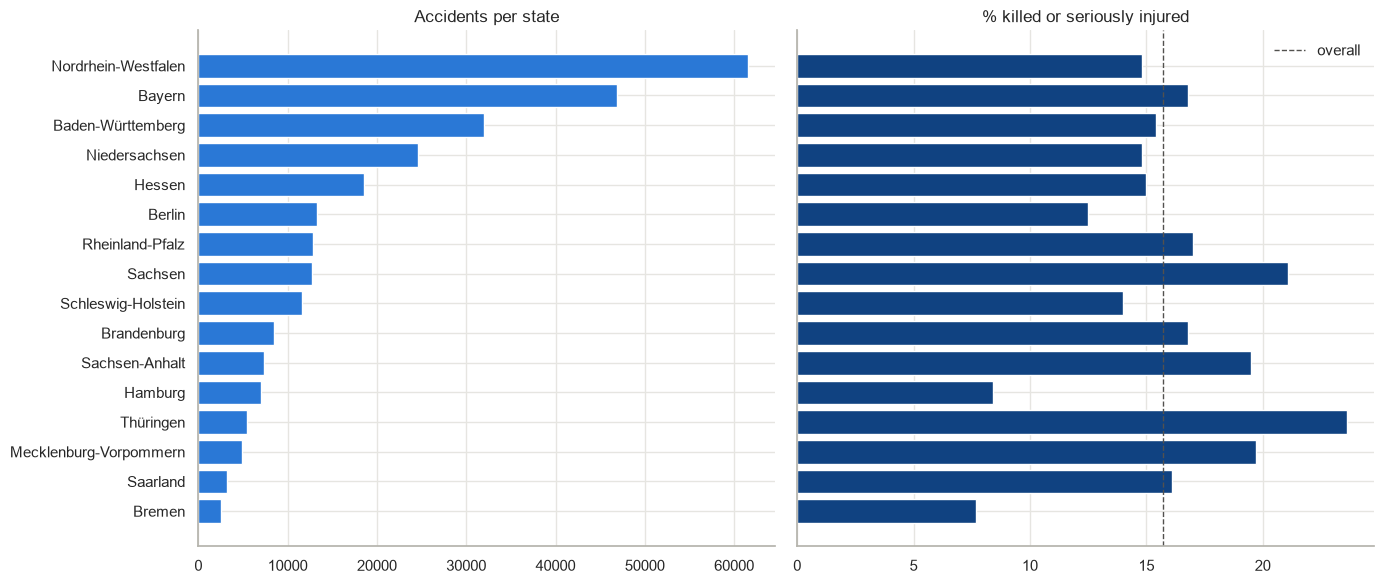

In [25]:
by_state = dfl.groupby("ULAND", observed=True).agg(n=("fatal", "size"), ks=("killed_or_serious", "mean"),
                                                   fatal=("fatal", "mean")).sort_values("n", ascending=False)
by_state["ks"] = (by_state["ks"] * 100).round(1); by_state["fatal"] = (by_state["fatal"] * 100).round(2)
display(by_state.rename(columns={"ks": "% killed/serious", "fatal": "% fatal"}))

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
axes[0].barh(by_state.index.astype(str), by_state["n"], color=BLUE); axes[0].set_title("Accidents per state")
axes[1].barh(by_state.index.astype(str), by_state["ks"], color="#104281")
axes[1].axvline(dfl["killed_or_serious"].mean() * 100, color="#52514e", ls="--", lw=1, label="overall")
axes[1].set_title("% killed or seriously injured"); axes[1].legend(frameon=False)
axes[0].invert_yaxis(); plt.tight_layout(); plt.show()

City states (Berlin, Hamburg, Bremen) have many accidents but low severity; rural, large-area states have markedly higher severity – speed and road type likely play a role.

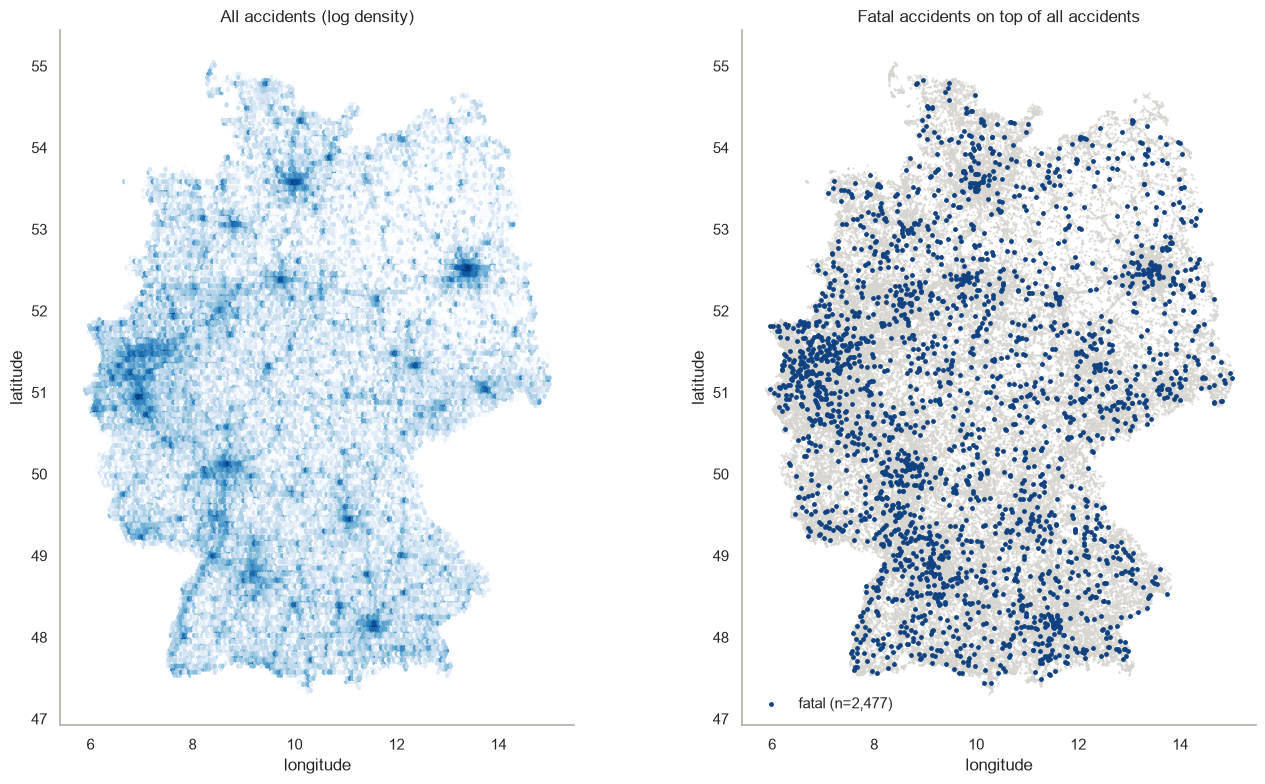

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14, 8))
axes[0].hexbin(df["XGCSWGS84"], df["YGCSWGS84"], gridsize=180, bins="log", cmap="Blues", mincnt=1)
axes[0].set_title("All accidents (log density)")
axes[1].scatter(df["XGCSWGS84"], df["YGCSWGS84"], s=0.2, color="#d6d5cf", rasterized=True)
f = df[df["UKATEGORIE"] == 1]
axes[1].scatter(f["XGCSWGS84"], f["YGCSWGS84"], s=6, color="#104281", label=f"fatal (n={len(f):,})")
axes[1].set_title("Fatal accidents on top of all accidents"); axes[1].legend(frameon=False, loc="lower left")
for ax in axes:
    ax.set_aspect(1.6); ax.set_xlabel("longitude"); ax.set_ylabel("latitude"); ax.grid(False)
plt.tight_layout(); plt.show()

## 10. Associations between features

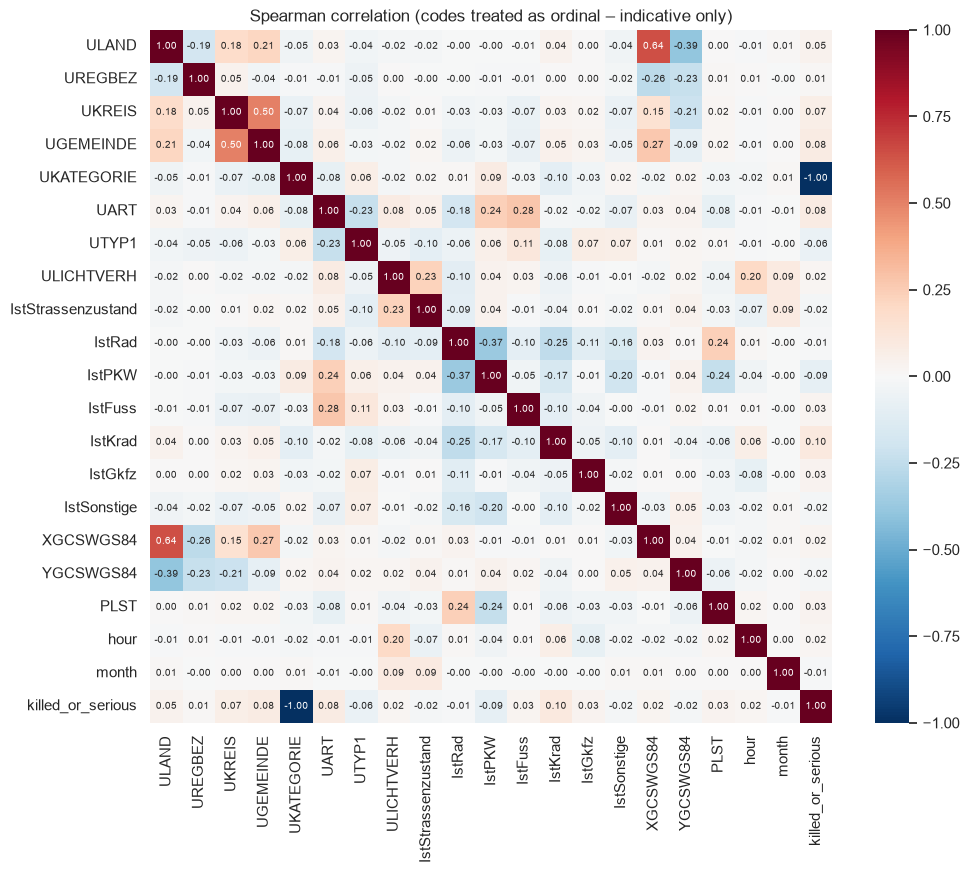

In [27]:
num = df.drop(columns=["UIDENTSTLAE", "datetime", "LINREFX", "LINREFY", "date_mismatch"]).assign(
    hour=dfl["hour"], month=dfl["month"], killed_or_serious=dfl["killed_or_serious"].astype(int))
corr = num.corr(method="spearman")
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 7}, ax=ax)
ax.set_title("Spearman correlation (codes treated as ordinal – indicative only)"); plt.show()

In [28]:
# a few pairs that are redundant by definition
print(pd.crosstab(dfl["UART"], df["IstFuss"]))
print()
print(pd.crosstab(dfl["PLST"], df["IstRad"]))

IstFuss                                        0      1
UART                                                   
other kind                                 48083   2080
with starting/stopping/stationary vehicle  14962    162
with vehicle ahead/waiting                 42325    123
with vehicle moving laterally, same dir.   15231     44
with oncoming vehicle                      18908     77
with turning/crossing vehicle              72384    293
vehicle–pedestrian                           156  20948
with obstacle on carriageway                2840    152
leaving carriageway right                  21191    101
leaving carriageway left                   12890     57

IstRad                   0      1
PLST                             
regular             183486  82130
advanced (bicycle)       0   7391


## 11. Summary

**Data quality**
* 273,007 accidents, 25 columns, no missing values, no duplicate rows/IDs; all coordinates inside Germany.
* `UIDENTSTLAE` must be read as string, coordinates need `decimal=","`.
* The day-of-month is only encoded in the ID (`LL YYMMDD…`). Combined with year/month/hour it gives a full `datetime`; it agrees with the weekday column for >99.99 % of rows (mismatches flagged in `date_mismatch`). The four original date columns were dropped.
* `UJAHR` is constant; `UREGBEZ` is 0 for states without administrative regions; `UKREIS`/`UGEMEINDE` are only unique together with the higher levels (build a combined key if used).
* `PLST`, `LINREFX/Y` and the WGS84 coordinates are location metadata, not accident characteristics. `PLST = 2` only occurs for bicycle accidents → leakage-like redundancy with `IstRad`.

**Findings**
* Severity is very imbalanced: 0.9 % fatal, 14.8 % seriously injured, 84.3 % slightly injured.
* Volume peaks at commuting hours, on weekdays and in summer; **severity** peaks at night and at weekends. Darkness raises severity only slightly (17.3 % vs. 15.3 %).
* Wet or wintry roads are *not* associated with more severe accidents (slightly less) – probably drivers slow down.
* Leaving the carriageway (≈26 %) and collisions with oncoming vehicles (24 %, 2.5 % fatal) are the most severe kinds of accident; rear-end and parking-type collisions are frequent but mild (8–9 %).
* Motorcycle, goods-vehicle and pedestrian involvement increase severity; car involvement is the most common and least severe.
* Rural eastern states (Thüringen 23.6 %, Sachsen 21.1 %, Meck.-Vorpommern 19.7 %) show much higher severity than city states (Bremen 7.7 %, Hamburg 8.4 %).

**Next steps for modelling**: binary target `killed_or_serious`, cyclical encoding of hour/month, one-hot encoding of `UART`/`UTYP1`/`ULAND`, class-imbalance handling, and spatial features (e.g. urban vs. rural from municipality codes or point density).